In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

# 1. California cities (Water area leaders)

In [2]:
data_cities = pd.read_csv("california_cities.csv")
data_cities.head()

,Unnamed: 0,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


In [3]:
data_cities[['area_water_km2', 'area_water_sq_mi']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 482 entries, 0 to 481
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   area_water_km2    478 non-null    float64
 1   area_water_sq_mi  481 non-null    float64
dtypes: float64(2)
memory usage: 7.7 KB


In [4]:
df_cities_not_nan = data_cities.copy()

In [5]:
df_cities_not_nan["area_water_km2"] = df_cities_not_nan["area_water_km2"].fillna(df_cities_not_nan["area_water_sq_mi"] * 2.589)

In [6]:
df_cities_not_nan['area_water_km2'].isna().sum()

np.int64(0)

In [7]:
data_high_water_area = df_cities_not_nan.sort_values("area_water_km2", ascending=False)[['city', 'area_water_km2']].reset_index(drop=True)

five top 

In [8]:
chart = data_high_water_area.iloc[0:5]
data_high_water_area.head(5)

,city,area_water_km2
0,SanFrancisco,479.01678
1,SanDiego,122.27000
2,LosAngeles,88.00000
3,NewportBeach,75.55700
4,Coronado,64.06200


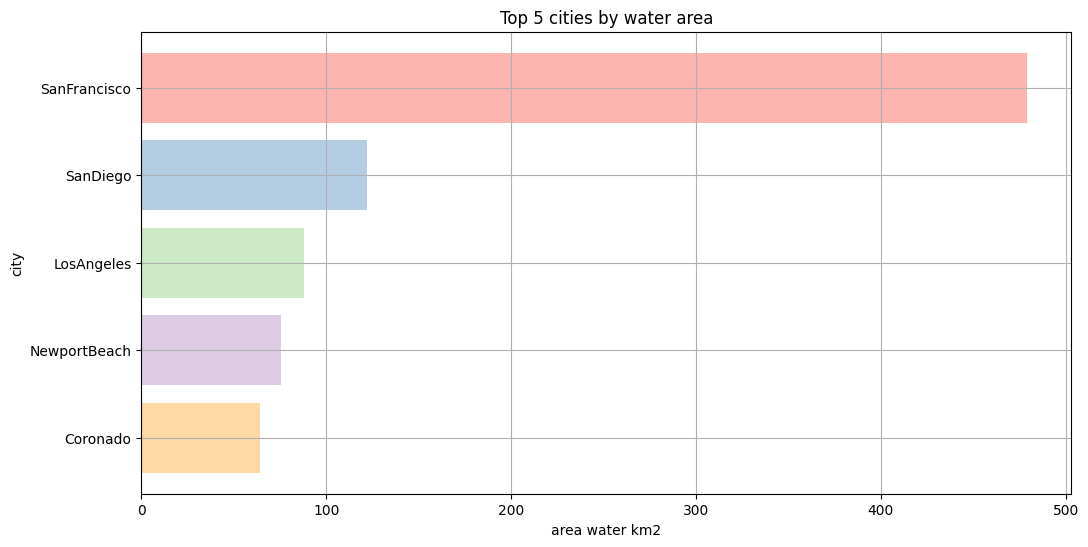

In [9]:
plt.figure(figsize=(12, 6))
colors = plt.cm.Pastel1.colors[:len(chart)]
plt.barh(
    chart["city"],
    chart["area_water_km2"],
    align="center",
    color=colors
)
plt.axis()
plt.gca().invert_yaxis()
plt.title("Top 5 cities by water area")
plt.xlabel("area water km2")
plt.ylabel("city")
plt.grid()
plt.show()

# 2. Billionaires (Other industries)

In [10]:
data_billioonaire = pd.read_csv("Billionaire.csv")
data_billioonaire.head()

,Name,NetWorth,Country,Source,Rank,Age,Industry
0,Jeff Bezos,$177 B,United States,Amazon,1,57.0,Technology
1,Elon Musk,$151 B,United States,"Tesla, SpaceX",2,49.0,Automotive
2,Bernard Arnault & family,$150 B,France,LVMH,3,72.0,Fashion & Retail
3,Bill Gates,$124 B,United States,Microsoft,4,65.0,Technology
4,Mark Zuckerberg,$97 B,United States,Facebook,5,36.0,Technology


In [11]:
data_billioonaire.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2755 entries, 0 to 2754
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      2755 non-null   object 
 1   NetWorth  2755 non-null   object 
 2   Country   2755 non-null   object 
 3   Source    2755 non-null   object 
 4   Rank      2755 non-null   int64  
 5   Age       2676 non-null   float64
 6   Industry  2755 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 150.8+ KB


there is no non value in Name and Industry

In [12]:
industry_frequency = data_billioonaire.groupby("Industry")["Name"].count().sort_values(ascending=False).reset_index()

In [13]:
top10 = industry_frequency.iloc[:10]
rest = industry_frequency.iloc[10:]

other_row = pd.DataFrame({
    "Industry": ["Other"],
    "Name": [rest["Name"].sum()],
})

industry_frequency_top = pd.concat([top10, other_row], ignore_index=True)

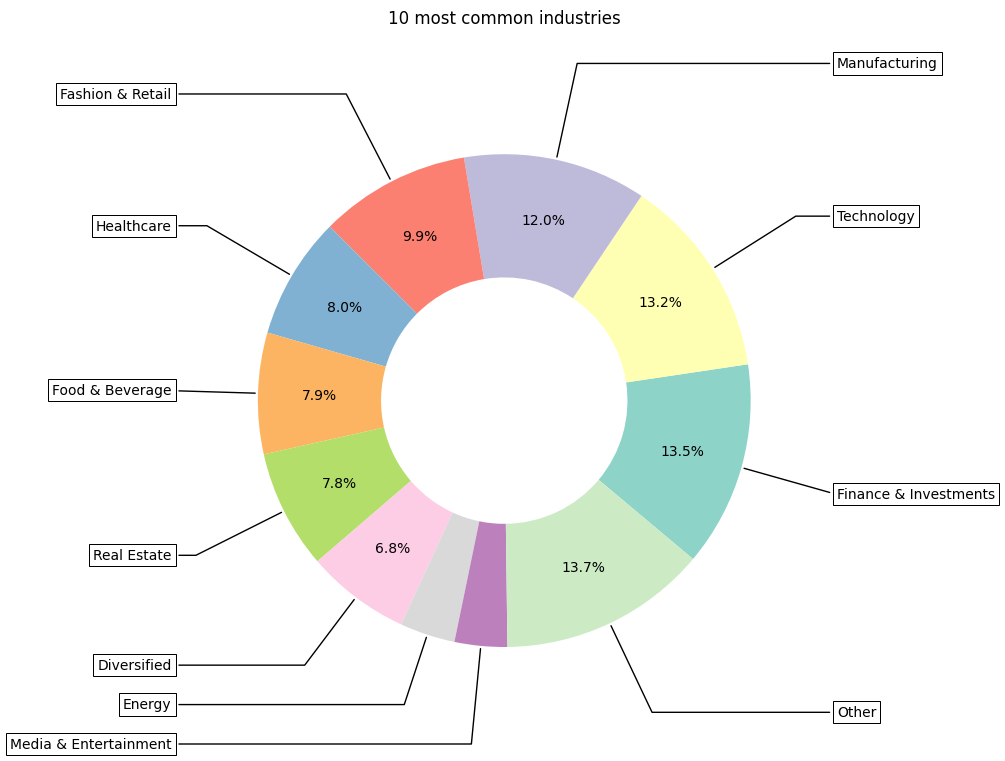

In [14]:
import numpy as np
import matplotlib.pyplot as plt

values = industry_frequency_top["Name"]
labels = industry_frequency_top["Industry"]
total = values.sum()

def show_pct(pct):
    return f"{pct:.1f}%" if pct > 5 else ""

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(aspect="equal"))

wedges, texts, autotexts = ax.pie(
    values,
    wedgeprops=dict(width=0.5),
    startangle=-40,
    colors=plt.cm.Set3.colors[:len(values)],
    autopct=show_pct,
    pctdistance=0.75
)

bbox_props = dict(boxstyle="square,pad=0.3", fc="w", ec="k", lw=0.72)
kw = dict(arrowprops=dict(arrowstyle="-"), bbox=bbox_props, zorder=0, va="center")

items = []
for i, p in enumerate(wedges):
    ang = (p.theta2 - p.theta1) / 2. + p.theta1
    x = np.cos(np.deg2rad(ang))
    y = np.sin(np.deg2rad(ang))
    items.append({"i": i, "ang": ang, "x": x, "y": y, "ty": 1.4 * y, "side": 1 if x >= 0 else -1})

min_gap = 0.16
for side in (1, -1):
    group = sorted([it for it in items if it["side"] == side], key=lambda it: it["ty"])
    for prev, cur in zip(group, group[1:]):
        if cur["ty"] - prev["ty"] < min_gap:
            cur["ty"] = prev["ty"] + min_gap

for it in items:
    kw["arrowprops"].update({"connectionstyle": f"angle,angleA=0,angleB={it['ang']}"})
    ax.annotate(
        labels.iloc[it["i"]],
        xy=(it["x"], it["y"]),
        xytext=(1.35 * it["side"], it["ty"]),
        horizontalalignment="left" if it["side"] == 1 else "right",
    #    fontsize=12,
        **kw,
    )

ax.set_title("10 most common industries", pad=50)
plt.show()

# 3. Online retail (Monthly Retention Rate)


In [15]:
data_customer = pd.read_csv("OnlineRetail.csv", encoding="ISO-8859-1")
data_customer.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [16]:
data_customer = data_customer[data_customer["Country"] == 'United Kingdom']
data_customer.info()

<class 'pandas.core.frame.DataFrame'>
Index: 495478 entries, 0 to 541893
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    495478 non-null  object 
 1   StockCode    495478 non-null  object 
 2   Description  494024 non-null  object 
 3   Quantity     495478 non-null  int64  
 4   InvoiceDate  495478 non-null  object 
 5   UnitPrice    495478 non-null  float64
 6   CustomerID   361878 non-null  float64
 7   Country      495478 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 34.0+ MB


In [17]:
print("we missing", data_customer["CustomerID"].isna().sum(), "customerID")

we missing 133600 customerID


In [18]:
data_customer[data_customer['CustomerID'].isna()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,12/1/2010 14:32,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,12/1/2010 14:32,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,12/1/2010 14:32,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,12/1/2010 14:32,1.66,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
541536,581498,85099B,JUMBO BAG RED RETROSPOT,5,12/9/2011 10:26,4.13,NaN,United Kingdom
541537,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,12/9/2011 10:26,4.13,NaN,United Kingdom
541538,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,12/9/2011 10:26,4.96,NaN,United Kingdom
541539,581498,85174,S/4 CACTI CANDLES,1,12/9/2011 10:26,10.79,NaN,United Kingdom


We need CustomerID to track each customer across months, so we drop the rows where it is missing

In [19]:
data_not_non_ID = data_customer.dropna(subset=["CustomerID"])

In [20]:
data_not_non_ID ["InvoiceDate"]= pd.to_datetime(data_not_non_ID['InvoiceDate']).dt.to_period("M")
cross = pd.crosstab(data_not_non_ID["CustomerID"], data_not_non_ID["InvoiceDate"])

C:\Users\Victus\AppData\Local\Temp\ipykernel_23256\3981421539.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_not_non_ID ["InvoiceDate"]= pd.to_datetime(data_not_non_ID['InvoiceDate']).dt.to_period("M")


In [21]:
active_customers = cross > 0
months = active_customers.columns
retained_counts = {}

for prev, cur in zip(months[:-1], months[1:]):
    retained_ids = active_customers[(active_customers[prev] > 0) & (active_customers[cur] > 0)].index
    retained_counts[str(cur)] = len(retained_ids)

total_active = active_customers.sum()
total_active.index = total_active.index.astype(str)

retained_counts = pd.Series(retained_counts)
retained_counts = pd.DataFrame({
    "Month": retained_counts.index,
    "RetainedCustomers": retained_counts.values,
})
retained_counts["TotalActiveCustomers"] = retained_counts["Month"].map(total_active)

retained_counts

,Month,RetainedCustomers,TotalActiveCustomers
0,2011-01,322,684
1,2011-02,263,714
2,2011-03,305,923
3,2011-04,310,817
4,2011-05,369,985
5,2011-06,417,943
6,2011-07,379,899
7,2011-08,391,867
8,2011-09,417,1177
9,2011-10,502,1285


In [22]:
retained_counts['RetentionRate'] = retained_counts["RetainedCustomers"] / retained_counts["TotalActiveCustomers"]
retained_counts = retained_counts[retained_counts["Month"] != "2011-12"]
retained_counts

,Month,RetainedCustomers,TotalActiveCustomers,RetentionRate
0,2011-01,322,684,0.470760
1,2011-02,263,714,0.368347
2,2011-03,305,923,0.330444
3,2011-04,310,817,0.379437
4,2011-05,369,985,0.374619
5,2011-06,417,943,0.442206
6,2011-07,379,899,0.421580
7,2011-08,391,867,0.450980
8,2011-09,417,1177,0.354291
9,2011-10,502,1285,0.390661


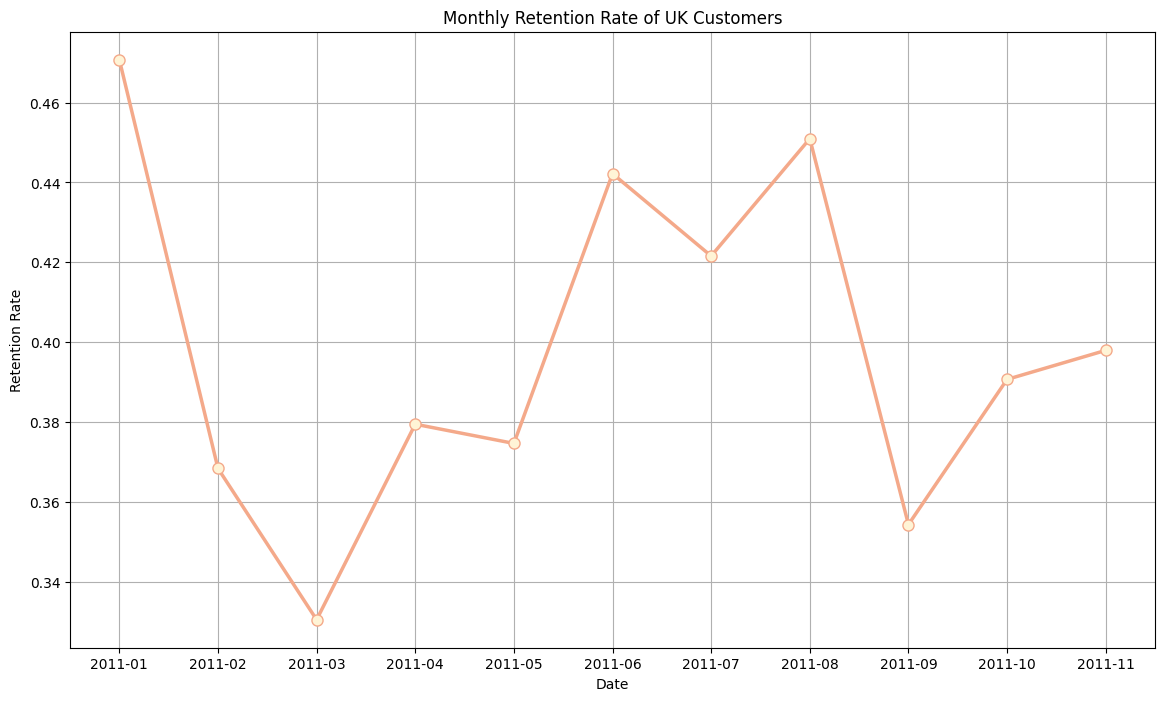

In [23]:
plt.figure(figsize=(14, 8))
plt.plot(retained_counts["Month"].astype(str), retained_counts["RetentionRate"],
    color="#F4A98A",
    linewidth=2.5,
    marker="o",
    markersize=8,
    markerfacecolor="#FFF4D6"
    )
plt.xlabel("Date")
plt.ylabel("Retention Rate")
plt.grid()
plt.title("Monthly Retention Rate of UK Customers")
plt.show()